# Implementing a GPT model from scratch to generate text

- One of the popular LLM is GPT(generative preprocessing text), built over the large nueral networks trained to predict the next work.
- For it the main thing is the `transformer` architecture.
- the term `parameters` refers to the trainable weights of the model. These weights are essentially the internal variables of the model that are adjusted and optimized during the training process to minimize a specific loss function. This optimization allows the model to learn from the training data.

![1. Gpt Architecture](../images/1.GptArch.png)

- `For example, in a neural network layer that is represented by a 2,048 × 2,048–dimensional matrix (or tensor) of weights, each element of this matrix is a parameter. Since there are 2,048 rows and 2,048 columns, the total number of parameters in this layer is 2,048 multiplied by 2,048, which equals 4,194,304 parameters.`

In [7]:
GPT_CONFIG_124M = {
 "vocab_size": 50257, # Vocabulary size
 "context_length": 1024, # Context length
 "emb_dim": 768, # Embedding dimension
 "n_heads": 12, # Number of attention heads
 "n_layers": 12, # Number of layers
 "drop_rate": 0.1, # Dropout rate
 "qkv_bias": False # Query-Key-Value bias
}

# Gpt architecture flow

![2. Gpt Flow](../images/2.GptFlow.png)

#  A placeholder GPT model architecture class

In [8]:
import torch
import torch.nn as nn
class DummyTransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
    def forward(self, x):
        return x

class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()
    def forward(self, x):
        return x
        
        
class dummyGPTModel(nn.Module):
    def __init__(self, cfg ):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential( *[DummyTransformerBlock(cfg)for _ in range(cfg["n_layers"])])
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
        cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self,in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        print(f"token embedding shape {tok_embeds.shape}")
        print(f"position embedding shape {pos_embeds.shape}")
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits
    

- the DummyGPTModel class consists of token and positional embeddings, dropout, a series of transformer blocks (DummyTransformerBlock), a final layer normalization (DummyLayerNorm), and a linear output layer (out_head).

In [9]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")
batch = []
txt1 = "Every effort moves you"
txt2 = "Every day holds a"

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0) #returns another array of arrays.


                                                        

- now this batch adding to the 124M above dummy gpt model.

In [10]:
torch.manual_seed(123)
model = dummyGPTModel(GPT_CONFIG_124M)
logits = model(batch)
logits, logits.shape

token embedding shape torch.Size([2, 4, 768])
position embedding shape torch.Size([4, 768])


(tensor([[[-1.2034,  0.3201, -0.7130,  ..., -1.5548, -0.2390, -0.4667],
          [-0.1192,  0.4539, -0.4432,  ...,  0.2392,  1.3469,  1.2430],
          [ 0.5307,  1.6720, -0.4695,  ...,  1.1966,  0.0111,  0.5835],
          [ 0.0139,  1.6754, -0.3388,  ...,  1.1586, -0.0435, -1.0400]],
 
         [[-1.0908,  0.1798, -0.9484,  ..., -1.6047,  0.2439, -0.4530],
          [-0.7860,  0.5581, -0.0610,  ...,  0.4835, -0.0077,  1.6621],
          [ 0.3567,  1.2698, -0.6398,  ..., -0.0162, -0.1296,  0.3717],
          [-0.2407, -0.7349, -0.5102,  ...,  2.0057, -0.3694,  0.1814]]],
        grad_fn=<UnsafeViewBackward0>),
 torch.Size([2, 4, 50257]))

- The output tensor has two rows corresponding to the two text samples. Each text sample consists of four tokens; each token is a 50,257-dimensional vector, which matches the size of the tokenizer’s vocabulary.

# Normalizing activations with layer normalization
- Sometimes training deep nueral nets are hard because, layer to layer some where gradients may vanish.
- It difficult for the network to effectively adjust its weights, which means the learning process struggles to find a set of parameters
(weights) for the neural network that minimizes the loss function
- the network has difficulty learning the underlying patterns in the data to a degree that would allow it to make accurate predictions or decisions. 
- `Layer normalization is to improve the stability and efficiency of neural network training`.
- The main idea behind the layer normalisation is to adjust the activations of the neural network layer to have a mean of 0 and a variance of 1, also known as unit variance.
- In GPT-2 and modern transformer architectures, layer normalization is typically applied before and after the multi-head attention module.
![4. Layer Norm](../images/4.layerNorm.png)

# A deep explanation on layer norm
- sometimes values in layer like this [100, 105, 110, 115, 120] and also [1000, 1050, 1100, 1150, 1200] in neural network values are sometimes are much larger and other time that is much smaller.
- With these numbers training is difficult.
- So we need to take those numbers into same scale. so we normalise using by substracting mean and dividing with the standard deviation.
- After this still layernorm has two params scale and shift.
- Layer was like this y=mx+c , Because the network should have the freedom to decide what scale and shift work best for learning.
- `Without normalization, the values flowing through many transformer layers can become poorly scaled, making optimization harder`.
- LayerNorm = Keeping the numbers manageable while the brain learns

In [11]:
# reconstructing above diagram

torch.manual_seed(123)
x = torch.rand(2,5)
layer = nn.Sequential(nn.Linear(5,6), nn.ReLU())
out = layer(x)
x, out

(tensor([[0.2961, 0.5166, 0.2517, 0.6886, 0.0740],
         [0.8665, 0.1366, 0.1025, 0.1841, 0.7264]]),
 tensor([[0.0000, 0.0000, 0.4091, 0.6587, 0.3914, 0.0000],
         [0.0000, 0.0000, 0.1902, 0.3182, 0.6486, 0.0000]],
        grad_fn=<ReluBackward0>))

- This every linear layer has  a non linear ReLU(rectified linear unit) function, it is the standard activation function in NN.
- it uses the activation function as f(x)=max(0,x). eliminates the -ves.
- It introduces necessary non-linearity, enabling the network to learn complex patterns and decision boundaries.
- We calculate the mean and variance of ReLU activations to ensure stable signal propagation and prevent vanishing or exploding gradients during network initialization and training.

In [14]:
mean = out.mean(dim=-1, keepdim=True) # means along rows
var = out.var(dim=-1, keepdim=True)

mean, var

(tensor([[0.2432],
         [0.1928]], grad_fn=<MeanBackward1>),
 tensor([[0.0799],
         [0.0670]], grad_fn=<VarBackward0>))

- we use `keepdim` for the output tensor retains the same number of dimensions as the input tensor, even though the operation reduces the tensor along the dimension specified via dim.
- now without dim all outputs are got in single tensor as 1 x 2 instead of 2 x 1.
- dim=-1 or 1 calculates mean across the rows, 0 is for cols.
- let’s apply layer normalization to the layer outputs we obtained earlier. The operation consists of subtracting the mean and dividing by the square root of the variance .

In [16]:
out_norm = (out-mean)/var**0.5
mean_last = out_norm.mean(dim=-1, keepdim=True)
var_last = out_norm.var(dim=-1, keepdim=True)
print("Normalized layer outputs:\n", out_norm)
mean_last, var_last

Normalized layer outputs:
 tensor([[-0.8603, -0.8603,  0.5869,  1.4698,  0.5242, -0.8603],
        [-0.7450, -0.7450, -0.0102,  0.4844,  1.7608, -0.7450]],
       grad_fn=<DivBackward0>)


(tensor([[ 2.9802e-08],
         [-1.9868e-08]], grad_fn=<MeanBackward1>),
 tensor([[1.0000],
         [1.0000]], grad_fn=<VarBackward0>))

- `sci_mode` to improve readability for smallest values with e , upto -5 powers of 10

In [17]:
torch.set_printoptions(sci_mode=False)
print("Mean:\n", mean_last)
print("Variance:\n", var_last)

Mean:
 tensor([[ 0.0000],
        [-0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


# A layer normalisation class

In [18]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True,unbiased=False)
        norm_x = (x-mean)/torch.sqrt(var + self.eps)
        return self.scale * x + self.shift

- Here the eps is added to avoid the zero divisible error.
- scale and shift are two trainable parameters, that are same dim of the input, those are adjusted during the training and improve model performance.
- This allows the model to learn appropriate scaling and shifting that best suit the
data it is processing.

# Why we need activation function

- A neural network needs to learn complicated relationships.
- This is where activation functions help.
- Activation functions introduce non-linearity into neural networks.
- linearity is just like finding the direct relationships, all times that's not possible. so adding non linearity.
- Without activation functions : Multiple linear layers collapse into one linear transformation. The network has limited ability to represent complex patterns.
- With activation functions : Each layer can introduce new non-linear transformations. Stacking them allows the network to represent much more complicated relationships.

In [19]:
torch.manual_seed(123)
batch_example = torch.rand(2, 5)
ln = LayerNorm(emb_dim=5)
print(batch_example)
out=ln(batch_example)
mean = out.mean(dim=-1, keepdim=True)
var = out.var(dim=-1,unbiased=False, keepdim=True)
mean, var

tensor([[0.2961, 0.5166, 0.2517, 0.6886, 0.0740],
        [0.8665, 0.1366, 0.1025, 0.1841, 0.7264]])


(tensor([[0.3654],
         [0.4032]], grad_fn=<MeanBackward1>),
 tensor([[0.0460],
         [0.1057]], grad_fn=<VarBackward0>))

# Implementing feedforward with GELU
- Historically ReLU - (Rectified linear unit) used as activation functions in the deep learning.
- Now in LLMs along with ReLU GELU-(Gaussian error linear unit) and SwiGLu- (Swish-gated linear unit).
- GELU and SwiGLU are more complex and smooth activation functions incorporating Gaussian and sigmoid-gated linear units. They offer improved performance for deep learning models, unlike the simpler ReLU.

# implementing GeLU activation function


In [20]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(torch.sqrt(torch.tensor(2.0 / torch.pi)) * (x + 0.044715 * torch.pow(x, 3))))

In [28]:
pip install matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-macosx_10_15_universal2.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl (283 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp314-cp314-macosx_10_15_universal2.whl (3.1 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl (64 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 6.1 MB/s  0:00:006.2 MB/s eta 0:00:01:01
Us

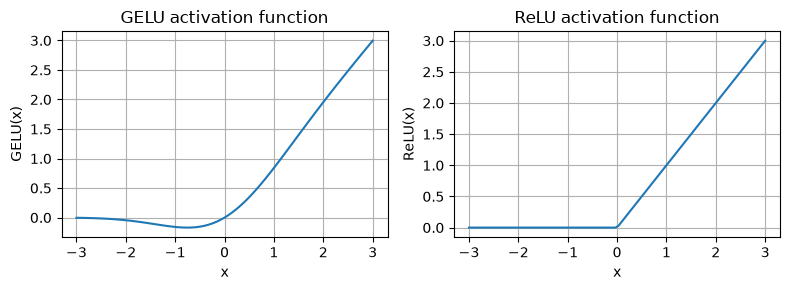

In [21]:
import matplotlib.pyplot as plt
gelu, relu = GELU(), nn.ReLU()

x = torch.linspace(-3, 3, 100) # creating 100 points between -3 and 3
y_gelu, y_relu = gelu(x), relu(x)
plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)
plt.tight_layout()
plt.show()


# GELU vs ReLU
![4. GELU and ReLu graphs](../images/5.GELUvsReLU.png)

- The smoothness of GELU can lead to better optimization properties during training,as it allows for more nuanced adjustments to the model’s parameters.
- In ReLU graph is sharper and harder due to the sharp zero untill the value is >0.
- In GELU it still allows the smaller values and negative values for the learning unlike the ReLU.
- This characteristic means that during the training process, neurons that receive negative input can still contribute to
the learning process, albeit to a lesser extent than positive inputs.

#  A feed forward neural network module

In [22]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4*cfg["emb_dim"]),
            GELU(),
            nn.Linear(4* cfg["emb_dim"],cfg["emb_dim"]),
        )
        #input to output 
        # gelu
        #output to input
    def forward(self, x):
        return self.layers(x)

![6. Feedforward](../images/6.feedforward.png)
![8. Feedforward](../images/8.feedforward.png)

In [23]:
ffn = FeedForward(GPT_CONFIG_124M)
x = torch.rand(2, 3, 768)
out = ffn(x)
out.shape

torch.Size([2, 3, 768])

- The FeedForward module plays a crucial role in enhancing the model’s ability to learn from and generalize the data.
- Although the input and output dimensions of this module are the same, it internally expands the embedding dimension into a higherdimensional space through the first linear layer.
- This expansion is followed by a nonlinear GELU activation and then a contraction back to the original dimension with the second linear transformation. Such a design allows for the exploration of a richer representation space.

# Adding shortcut connections

- shortcut connections are also known as skip or residual connections.

- shortcut connections are originally proposed for the deep networks in computer vision , to avoid the vanishing gradients.

- Vanishing gradients: the gradients are progressively small where they are back propagating through each layer, it is difficult to train the model.
  
- `main reason for shortcut layers is, in the backpropagation the gradients become very small in the early layers. To resolve this issue, in the layers the output gradients are directly sending to other output layers. without passing in between any layers just by skipping one or more layers in the middle, that preserves the gradients.`

![7. Adding shortcut layers](../images/7.shortcutlayers.png)

In [24]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            # here we need to add layers. input and output connections.
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU())
            
        ])
    def forward(self, x):
        for layer in self.layers:
            layer_output = layer(x)
            # checking for the each layer, does it accepts the shortcut or not.
            if self.use_shortcut and x.shape == layer_output.shape :
                x = x+ layer_output # replaces old x and creates new, don't do inline modification
            else:
                x = layer_output
        return x

In [25]:
layer_sizes = [3, 3, 3, 3, 3, 1] 
sample_input = torch.tensor([[1., 0., -1.]])
torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(
 layer_sizes, use_shortcut=False
)
model_without_shortcut

ExampleDeepNeuralNetwork(
  (layers): ModuleList(
    (0-3): 4 x Sequential(
      (0): Linear(in_features=3, out_features=3, bias=True)
      (1): GELU()
    )
    (4): Sequential(
      (0): Linear(in_features=3, out_features=1, bias=True)
      (1): GELU()
    )
  )
)

# implementing a function for layers backward pass

In [27]:
def print_gradients(model, x):
    # forward pass
    output = model(x)
    target = torch.tensor([0.])
    # loss calculation
    loss = nn.MSELoss()
    loss = loss(output, target)
    #backward pass calculates the gradients
    loss.backward()

    for name, params in model.named_parameters():
        if 'weight' in name:
            print(f"each layer {name} params for the layer {params.grad.abs().mean().item()}")
            
    

- a loss function that computes how close the model output and a user-specified target

- when calling loss.backward(), PyTorch computes the loss gradient for each layer in the model.

In [29]:
print_gradients(model_without_shortcut, sample_input)

each layer layers.0.0.weight params for the layer 0.00040347169851884246
each layer layers.1.0.weight params for the layer 0.00024022319121286273
each layer layers.2.0.weight params for the layer 0.0014304080978035927
each layer layers.3.0.weight params for the layer 0.002797747263684869
each layer layers.4.0.weight params for the layer 0.010099290870130062


- the output in the layer1 is keep vanishing while after the back propagation this phenomenon is called the vanishing gradients.

In [30]:
torch.manual_seed(123)
model_with_shortcut =  ExampleDeepNeuralNetwork(
 layer_sizes, use_shortcut=True
)
print_gradients(model_with_shortcut, sample_input)

each layer layers.0.0.weight params for the layer 0.22169791162014008
each layer layers.1.0.weight params for the layer 0.20694105327129364
each layer layers.2.0.weight params for the layer 0.32896995544433594
each layer layers.3.0.weight params for the layer 0.2665732204914093
each layer layers.4.0.weight params for the layer 1.3258540630340576


- check here there is no such differences in earlier layers from last, in the with shortcut models.
- Shortcut connections are a core building block of very large models such as LLMs, and they will help facilitate more effective training by ensuring consistent gradient flow across layers when we train the GPT model.

#  Connecting attention and linear layers in a transformer block

- transformer is the main building block of the LLMs. we are here building it.
  
- now we need to integrate these all from multihead attention, layernorm, activations using GELU , feedforward and shortcuts in the transformer.

- The idea is that the self-attention mechanism in the multi-head attention block identifies and analyzes relationships between elements in the input sequence.

- In contrast, the feed forward network modifies the data individually at each position. This combination not only enables a more nuanced understanding and processing of the input but also enhances the model’s overall capacity for handling complex data patterns.

![9. basic transformers](../images/9.basictransformer.png)

#  The transformer block component of GPT

In [31]:
from MultiheadAttention import MultiHeadAttention 
import torch.nn as nn
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()

        #multi attention
        self.attention = MultiHeadAttention(
             d_in=cfg["emb_dim"],
             d_out=cfg["emb_dim"], 
             context_length=cfg["context_length"], 
             dropout=cfg["drop_rate"],
             num_heads=cfg["n_heads"],
             qkv_bias=cfg["qkv_bias"]
        )
        
        # layernorms
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        
        #feedforward

        self.ff = FeedForward(cfg)

        #shortcut
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # above transformer diagram in most crucial
        # for first part in the transformer
        shortcut = x
        x = self.norm1(x)
        x = self.attention(x)
        x = self.drop_shortcut(x)
        x = x+ shortcut

        # second round here feedforward added
        shortcut =x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        return x

        

- Layer normalization (LayerNorm) is applied before each of these two components, and dropout is applied after them to regularize the model and prevent overfitting. This is also known as Pre-LayerNorm.

- Older architectures, such as the original transformer model, applied layer normalization after the self-attention and feed forward networks
instead, known as Post-LayerNorm, which often leads to worse training dynamics.

In [32]:
torch.manual_seed(123)
x = torch.rand(2, 4, 768)
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)
print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


- based on it, input and output dimensions in the transformer are same, after it is processing, giving the same dimension as output. without altering thier shape through entire network.

- the shape preservation in the transformer block is the crucial , because , with the input and output same shape we can establish one to one relationship bw it.

#  Coding the GPT model

- in the starting of this chapter we added a dummygpt placeholder there transformer block and layernorms are dummy. but now we need replace those with our real blocks.

- This transformer block repeats 12 times in the gpt2 model, it depends on the n_layers in cofig. for each layer this transformer block in involved.

- 48 times transformer block repeated in the gpt2's biggest 1.5billion parameter model.

- The output from the final transformer block then goes through a final layer normalization step before reaching the linear output layer. This layer maps the transformer’s output to a high-dimensional space (in this case, 50,257 dimensions, corresponding to the model’s vocabulary size) to predict the next token in the sequence.

![10. Overall GPT flow](../images/10.gptflow.png)

# The GPT model architecture implementation

- let us do based on the gpt diagram

In [40]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
       # we layers
        #token emb, position emb, dropout

        # ok those are embeddings when create embeddings use the Embedding, for inputs use the torch.tensor
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"],cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        
        # transformer
        self.trf_block = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
        ) # here it creates a multiple blocks of the transformers in layers
        #final norm
        self.final_norm = LayerNorm(cfg["emb_dim"])
        
        #output layer
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx) # based on index that parts embeddings

        # The device setting will allow us to train the model on a CPU or GPU, depending on which device the input data sits on. 
        pos_embeds = self.pos_emb(
            torch.arange(seq_len, device = in_idx.device)
        )
        # in pos_emb an array of sequntial nums are used for the position vector.

        # input level and embeddings
        x = tok_embeds + pos_embeds

        #drop
        x = self.drop_emb(x)

        # transformer block
        x = self.trf_block(x)
        # this x passes through the created transformer blocks in the each layers.

        x = self.final_norm(x) # final layer normalisation to avoid the major differences in the numbers.
        logits = self.out_head(x)
        return logits
        

In [42]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
out = model(batch)
print(out.shape)
out

torch.Size([2, 4, 50257])


tensor([[[-0.1049, -1.0847,  1.4789,  ...,  1.3407, -3.1097,  1.5784],
         [-2.0828, -2.0404,  0.7310,  ..., -1.1128, -3.2376,  0.3685],
         [ 2.8269, -2.3972, -0.4261,  ..., -1.3775, -1.7258,  2.2686],
         [-1.8791,  1.7422,  1.3538,  ...,  1.7109, -3.0309, -0.1702]],

        [[-3.6606, -2.1983,  2.8718,  ...,  2.2964, -4.4943, -4.1810],
         [ 0.3576, -0.7723,  2.1565,  ...,  2.5737, -2.2454, -0.4953],
         [-0.3813,  2.2827, -0.4468,  ...,  3.7847, -1.1865, -0.1548],
         [-1.6377,  2.2884,  1.8514,  ...,  1.0214, -3.2636, -1.3424]]],
       grad_fn=<UnsafeViewBackward0>)

- Here For every token, the model produces 50,257 scores.
  
-  the relationship between a token's representation and all vocabulary words is learned during training through the final linear layer.

- `Matrix multiplication is what establishes the relationship between each token's 768-dimensional representation and every vocabulary token's 768-dimensional weight vector.`

- size is [2, 4, 50257] due to the size of token matrix= X=[4×768], size of the vocab = W=[50257×768], explored mmore dimensions in the forward layer,   but in the final layer after matrix multiplication, XW.transpose = [4 x 768] [768 x 50257] = [4 x 50257] this is how final shape relateed with the vocab_size.

-  let’s spend a bit more time with the model architecture itself and analyze its size.Using the numel() method, short for “number of elements,” we can collect the total number of parameters in the model’s parameter tensors:

In [68]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:}")

Total number of parameters: 163009536


# how does 163M came?
![11. Parameters compute](../images/11.parameters.png)

- but gpt2 has only 124M params, how come this 163M raise. this is due to `weight tying` which was used in the original GPT-2 architecture.

- It means that the original GPT-2 architecture reuses the weights from the token embedding layer in its output layer.

- like already token embeddings have all weights of the output layer weights, so final = total-output layer

![12. Weight tying](../images/12.weighttying.png)

In [69]:
out_params = sum(p.numel() for p in model.out_head.parameters())

print(f"total params {total_params} , output layer params {out_params} final params in the gpt2 {total_params-out_params}")

total params 163009536 , output layer params 38597376 final params in the gpt2 124412160


## Excercise: Number of parameters in feed forward and attention modules
`Calculate and compare the number of parameters that are contained in the feed forward module and those that are contained in the multi-head attention module.`

In [70]:
# model
feed_ff_params, mha_params = 0,0
for i in range(GPT_CONFIG_124M["n_heads"]):
    feed_ff_params += sum(p.numel() for p in model.trf_block[i].attention.parameters())
    mha_params += sum(p.numel() for p in model.trf_block[i].ff.parameters())
print(f"feedforward params {feed_ff_params} , mutlihead attention layer params {mha_params} final params in the gpt2 transformer {feed_ff_params+ mha_params}")

feedforward params 28320768 , mutlihead attention layer params 56669184 final params in the gpt2 transformer 84989952


## memory computation

- let’s compute the memory requirements of the 163 million parameters in our GPTModel object:

In [71]:
total_size_bytes = total_params * 4
total_size_mb = total_size_bytes / (1024 * 1024)
print(f"Total size of the model: {total_size_mb:.2f} MB")

Total size of the model: 621.83 MB
